# Political violence - subnational predictive modelling for Nigeria using ACLED data, mid term project


- Two sections: one is data exploration and then create the weekly grid
- Weekly grid to then create the data viz and EDA.

# Motivation:
- Using a machine learning methods for subnational conflict forecasting for early warning at a subnational level (admin1) using ACLED data for Nigeria.
- ACLED from dates 1997-2026, admin 1 level.
- Context of Nigeria: 

# Structure of notebook:
- The notebooks here are organised to the CRISP-DM framework covering: business understanding, data cleaning and preparation, modelling, evaluation and deployment.
- The first section goes through the motivation of the research question. 
- Second section foes through data understanding and cleaning
- Third section goes through the EDA.

# 0. Objective
 
This project builds a conflict forecasting model for Nigeria. The aim is to estimate, at the **state-week** level, the likelihood that political violence will cause fatalities, so that early-warning, humanitarian, and policy actors can prioritise attention and resources before violence escalates.
 
**Key questions**
- Where and when is fatal political violence most likely to occur?
- How much predictive signal comes from a state's own violence history?
- Does the electoral calendar measurably increase the risk of fatal violence?
**Intended users:** conflict analysts, peacebuilding and humanitarian organisations, and election-monitoring bodies.


## 1. Context of Nigeria
 
Nigeria returned to democratic rule in 1999. Since 1989 it has experienced violence across three categories: state-based (including interstate and intrastate), non-state, and one-sided violence against civilians. The dominant forms and actors have shifted considerably over time.

### 1.1 Evolution of conflict
 
| Period | Dominant pattern | Key features |
|---|---|---|
| **1990s** | Non-state conflict, Niger Delta | Clashes between ethnic groups (e.g. Andoni and Ogoni) over oil-rich land, land ownership polarisation, and taxation of land and oil-facility employees. Boundary and land-settlement disputes led to Ogoni–Okrika and Ndoki–Ogoni clashes with 100+ fatalities. Communal clashes (e.g. Atyap and Hausa) spread along Muslim–Christian lines in the early to mid 1990s. |
| **1990s–2000s** | One-sided and non-state violence | Highest fatalities from the Odi massacre (Bayelsa State), carried out by the government against civilians amid disputes over resource control, oil pollution, and land degradation. Emergence of further armed groups. Rising Christian–Muslim tension (about 1,800 fatalities). Push to extend Sharia law in the north. Inter-ethnic conflicts (Hausa–Igbo, Ife–Modakeke, Jukun–Tiv). |
| **2000s–2010** | Rising organised violence | Violence rose steadily from 2009–2010 and escalated dramatically, peaking in 2014–2015. Fulani actors emerged as major participants (e.g. Birom–Fulani conflict in Plateau State). Sharia-related tensions and migration inflows in the north. |
| **2010–2014** | Insurgency | JAS/IS attacks in Maiduguri, Borno and Yobe widened in scope, with high civilian fatalities, targeting of religious leaders and groups, and suicide bombings in churches, markets, and public places. |
| **2015–2020s** | Multi-actor violence | The JAS–Yan Gora conflict (armed village youths vs JAS in Borno). Peak farmer–herder violence in the Middle Belt and central zones. In 2021, non-state violence caused the second-highest fatality count, exceeding one-sided violence, rising from almost 500 (2020) to over 900 (2021). The IS–JAS conflict was the most violent non-state conflict (300+ fatalities). By the 2020s banditry was among the most pressing security threats: village raids, extortion of farmers and miners, ransom kidnappings, and levies enforced by deadly attacks or mass abductions. |


### 1.3 Geographic hotspots
- **North-east:** Borno, Yobe (insurgency)
- **Middle Belt / central:** Plateau and surrounding states (farmer–herder, ethno-religious)
- **Niger Delta:** Bayelsa, Rivers and surrounding states (resource conflict)
- **North-west:** banditry and kidnapping
- **South-east:** separatist enforcement and militia activity

   ## 2. Elections and political violence
 
Elections are a recurring driver and a key explanatory feature for this project.
 
- **2011:** Deadliest post-election riots. After Goodluck Jonathan's victory over Muhammadu Buhari, three days of sectarian rioting across 12 northern states killed over 800 people, including election staff and youth corps members.
- **2015–2019:** The 2015 cycle recorded roughly 106 deaths. Violence surged in 2019, with over 620 fatalities during the broader campaign period.
- **2023:** Over 100 fatalities and 44 violent attacks on INEC offices and staff. Cult militias, regional security outfits, and separatist enforcement in the South East suppressed turnout to a historic low of around 25%.
**Implication for modelling:** electoral violence is not confined to polling day. It spans the pre-election campaign period, election week, and post-result period, and varies by region. The electoral feature should therefore reflect these phases rather than a simple yes/no flag.
 
 ## 3. Understanding general patterns of political violence
 
### 3.1 Problem definition
- **Unit of analysis:** state-week (Nigerian states and the FCT × calendar weeks)
- **Task:** binary classification, forecasting whether a state experiences a high-intensity week of political violence (more than 5 fatalities) in a given week
### 3.2 Target variable
- Equals **1** if total fatalities from political violence events in a state-week exceed **5** (i.e. ≥ 6), and **0** otherwise.
- **Rationale:** the threshold targets a *significant increase in conflict intensity* above the usual baseline, rather than the mere presence (0 vs 1+) of fatal violence. In Nigeria, low-level fatal incidents occur routinely in many states, so a "any fatality" target would label most hotspot state-weeks as positive and say little about escalation. A higher threshold focuses the model on severe weeks that matter most for early warning.
- **Trade-offs to check:**
  - Class imbalance will be more severe, since fewer state-weeks cross the threshold.
  - Results are sensitive to the cut-off, so run sensitivity checks (e.g. > 0, > 5, > 10) to show how conclusions change.
  - Fatality counts are sums across events in the week, so the rule is applied to the weekly total, not to a single event.
  - Consider whether a fixed threshold is fair across states with very different baselines, or whether a relative measure (e.g. above a state's rolling average) should be tested as an alternative.



### 3.3 Features
- **Historical political violence (time lags):** prior weeks' event counts and fatalities, at lags such as 1, 2, 4, and 8 weeks, plus rolling averages. These capture persistence and escalation.
- **Electoral period:** indicator(s) for pre-election, election week, and post-election windows.
- **Admin level:** For spatial differences

### 3.4 Exploratory analysis plan
1. **Distributions of the target and features**
   - Class balance: share of state-weeks with more than 5 fatalities (expect strong imbalance), alongside the distribution of weekly fatalities to justify the threshold.
   - Distribution of lagged counts and fatalities (expect heavy right skew and many zeros).
   - Variation across states, with hotspots vs persistently quiet states.
2. **Temporal patterns, to inform the train/test split**
   - Plot national and state-level fatal events over time to identify trends, structural breaks, and spikes (e.g. 2014–2015, 2021).
   - Compare patterns around election periods against non-election periods.
   - Use these to choose a **time-based split**: train on earlier periods and test on later ones, never splitting randomly. Make sure the test window contains both calm and high-violence weeks and, ideally, an election cycle.
3. **Relationships between features and target**
   - Association of lagged violence and electoral period with next-week high-intensity violence (more than 5 fatalities).

### 3.5 Modelling and evaluation considerations
- **Class imbalance:** use metrics beyond accuracy, such as precision, recall, F1, PR-AUC, and ROC-AUC. Consider class weighting or resampling.
- **Temporal validation:** rolling or expanding-window cross-validation to avoid leakage from future information.
- **Baselines:** compare against naive benchmarks, such as "same as last week" and "state's historical average rate".
- **Interpretability:** report feature importance so users can see whether history or elections drive predictions.

## 4. Success criteria
- The model beats naive persistence baselines on held-out, time-forward data.
- Predictions are well calibrated and useful for ranking states by risk each week.
- Findings on the role of election periods are clear and defensible.
## 5. Risks and limitations
- **Data quality:** reporting bias, underreporting in remote areas, and inconsistent fatality estimates across sources.
- **Rare events and imbalance:** forecasts for low-violence states may be unstable.
- **Non-stationarity:** actors and drivers have changed repeatedly (Niger Delta, insurgency, banditry), so older patterns may not generalise.
- **Limited features:** lags and electoral timing omit structural drivers (economic conditions, climate, governance, security deployments).
- **Ethical use:** forecasts should support prevention and protection, with care taken that predictions do not stigmatise regions or communities.
## 6. Open questions
- Which dataset and event definition will be used (e.g. ACLED or UCDP), and which event types count as "political violence"?
- Is the fixed threshold of more than 5 fatalities robust, or should sensitivity analysis and relative (baseline-adjusted) definitions be tested (see 4.2)?
- Forecast horizon: next week only, or several weeks ahead?
- Adding demographic features should be a next step. 



## CONTEXT OF NIGERIA
- what is the type of conflict prevelant?
- Al shabbab- which locations etc.
- In 1999 Nigeria returned to democratic leadership- since 1989 Nigeria has experienced, interstate, intrastate and non state/ one sided categorises types of violence
- 90s: non state conflicts between the Adoni and Ogoni ethnic groups in Niger-delta region, highest fatalities in nonstate conflict. Driven by oil wells that generate to nigeria's revenue, polarisation of land ownership of oil-rich areas, conflicts over taxation of land and employees at oil facilities.
    - As a rsult of boundary disputes and land settlements--> clashes between Ogoni- Okrika and Ndoki-Ogoni clshes, resulting in over 100 fatalities
    - Communal clashes between Atyab and Hausa ethnic communities, rise in fatality rates in the early to mid 1990s--> spread via religious lines between Muslim and Christian communities

- 90s to 2000s:
    - One sided and non state conflicts, highest fatalities to Odi masacare by govt of nigeria on civilians, town of Odi in Bayelsa state, resource in Nigera-Delta region over resource control and need for the federal government to address environmental pollution and land degradation fostered by oil mining. 
    - recon air craft which lead to death of 2,478 civilians- emergence of more armed grops. 
    - more religious tension between christians and muslims- accounted of 1,800 fatalities 
    - Sharia law sought to be imposed to northern region, non state conflicts- inter ethnic conflicts between hausa-igbo, ife-modakeke and jukun-tiv.

- 2000s - 2010:
    - Organised vilence rising steadily in 2009-2010 escalating dramatically and peaking in 2014-2015. 
    - 2010 - 2012 driven by non state conflcit, fulani emerged as a major actor, birom-fulani (cattle herder/muslims) conflict formed part of the larger patterns of ethnic and religious tensions in Plataeu sate (chrisitians). 
    - Sharia law in the north- triggered conflicts, influx of migrants. 
    - organised conflict at a high 2014- attacks by JAS/IS. JAS/ Maiduguri, borno states and yobe state- broaded its scope, by  JAS/IS high civilian fatalities- targeting religious leaders and groups. Increase in suicide bombings in churchs, markets and public places.

- 2015- 2020s:
    - JAS- Yan Gora conflict emanated as a results of clashes between armed youths within a village Borno state and JAS.
    - Peak in Farmer- Herder violence- clashes indentisified in the Middle belt and central zones between agricultural communiities. 
    - The non-state category of organized violence accounted for the second highest number of fatalities in 2021, exceeding fatalities in one-sided violence. Trends show a significant increase from almost 500 in 2020 to over 900 casualties in 2021. The IS - JAS conflict was notable as the most violent non-state conflict with over 300 fatalities.
    -  Both actors have predominantly been involved in clashes at the national, state and communal level in Nigeria and other border countries. 
    - By the 2020s, banditry had evolved into one of Nigeria’s most pressing security threats. Bandit groups raided villages, extorted farmers and miners, kidnapped residents for ransom, and communities had to pay levies or – if unable to pay – risked facing deadly attacks or mass abductions


### Elections
- 2011 — Deadliest Post-Election Riots. Following Goodluck Jonathan's victory over Muhammadu Buhari, three days of sectarian rioting across 12 northern states killed over 800 people, including election staff and youth corps members.
-  2015–2019 — Pre-Election Shifts and Targeted Attacks. While the 2015 cycle recorded roughly 106 deaths, violence surged again in 2019 with over 620 fatalities during the broader campaign period.
- 2023 — Voter Suppression and Institutional Attacks. The 2023 cycle recorded over 100 fatalities alongside 44 violent attacks on Independent National Electoral Commission (INEC) offices and staff. Cult militias, regional security outfits, and separatist enforcement in the South East suppressed voter turnout to a historic low of around 25%.



# 1. Data Cleaning and Prep

This section explores and cleans the political violence event data, then aggregates it to a weekly × Admin 1 (state) panel. No other dataset is merged in. We build the target (more than 5 fatalities in a state-week) and engineer features from the event data alone.
 
**Steps**
- **Explore:** check the structure, date range, event types, and the distribution of `fatalities`.
- **Clean:** handle missing values and duplicates, fix data types, standardise state names, and filter to political violence event types. Log rows removed at each step.
- **Aggregate:** group events by state and week, then build a complete state × week panel so weeks with no events are filled with 0.
- **Target:** `1` if weekly fatalities exceed 5, else `0`. Check class balance.
- **Features:** lagged fatalities and event counts, rolling windows, and electoral-period flags, using only past information to avoid leakage.
**Assumptions:** no events in a week is treated as no violence. Fatality figures are estimates, and the threshold of more than 5 is a modelling choice.

In [317]:
## import packages ##
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

In [318]:
df = pd.read_csv('/Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/mid-term-project/data/ACLED Data_2026-11-02_event_date_from_1997-01-01_event_date_to_2026-10-30.csv')

In [319]:
df.dtypes

week                    object
region                  object
country                 object
admin1                  object
event_type              object
sub_event_type          object
events                   int64
fatalities               int64
population_exposure     object
disorder_type           object
centroid_latitude      float64
centroid_longitude     float64
dtype: object

In [320]:
df.describe()

,events,fatalities,centroid_latitude,centroid_longitude
count,33125.000000,33125.000000,33125.000000,33125.000000
mean,1.700045,4.595381,8.621693,7.535886
std,1.690538,25.063785,2.504808,2.741954
min,1.000000,0.000000,-38.437000,-19.393000
25%,1.000000,0.000000,6.491000,5.878000
50%,1.000000,0.000000,8.133000,7.188000
75%,2.000000,2.000000,11.573000,8.816000
max,32.000000,2000.000000,12.708000,13.435000


In [321]:
# only interested in political violent events- look at the event types:
df['event_type'].unique()

array(['Battles', 'Explosions/Remote violence',
       'Violence against civilians', 'Protests', 'Riots',
       'Strategic developments'], dtype=object)

In [322]:
df = df[df["disorder_type"].str.contains("Political violence", case=False, na=False)]
# 1. Verify the exact unique values remaining in disorder_type
print(df["disorder_type"].value_counts())
# 2. Check how many rows remain vs. your original count
print(f"Remaining rows: {len(df):,}")

disorder_type
Political violence                    22492
Political violence; Demonstrations      198
Name: count, dtype: int64
Remaining rows: 22,690


In [323]:
df.head(5)

,week,region,country,admin1,event_type,sub_event_type,events,fatalities,population_exposure,disorder_type,centroid_latitude,centroid_longitude
0,1997-01-04,Western Africa,Nigeria,Bayelsa,Battles,Armed clash,1,1,0,Political violence,4.825,5.959
1,1997-01-04,Western Africa,Nigeria,Cross River,Battles,Armed clash,1,1,0,Political violence,5.791,8.414
2,1997-01-04,Western Africa,Nigeria,Delta,Battles,Armed clash,1,3,0,Political violence,5.760,6.327
3,1997-01-04,Western Africa,Nigeria,Kogi,Battles,Armed clash,1,3,0,Political violence,7.621,6.854
4,1997-01-04,Western Africa,Nigeria,Lagos,Explosions/Remote violence,Remote explosive/landmine/IED,1,2,0,Political violence,6.491,3.785


In [324]:
print("Number of states/territories:",
      df["admin1"].nunique())

print(df["admin1"].value_counts())

Number of states/territories: 38
admin1
Borno                        2458
Kaduna                       1224
Zamfara                      1059
Delta                         984
Katsina                       965
Plateau                       907
Benue                         891
Lagos                         881
Niger                         874
Rivers                        833
Federal Capital Territory     651
Sokoto                        620
Anambra                       602
Edo                           592
Yobe                          575
Kogi                          553
Adamawa                       548
Taraba                        545
Bayelsa                       516
Imo                           508
Ogun                          505
Kwara                         450
Enugu                         447
Ondo                          446
Nassarawa                     440
Oyo                           422
Kano                          380
Osun                          380
Cross Ri

## 1.1 Patterns across space and time

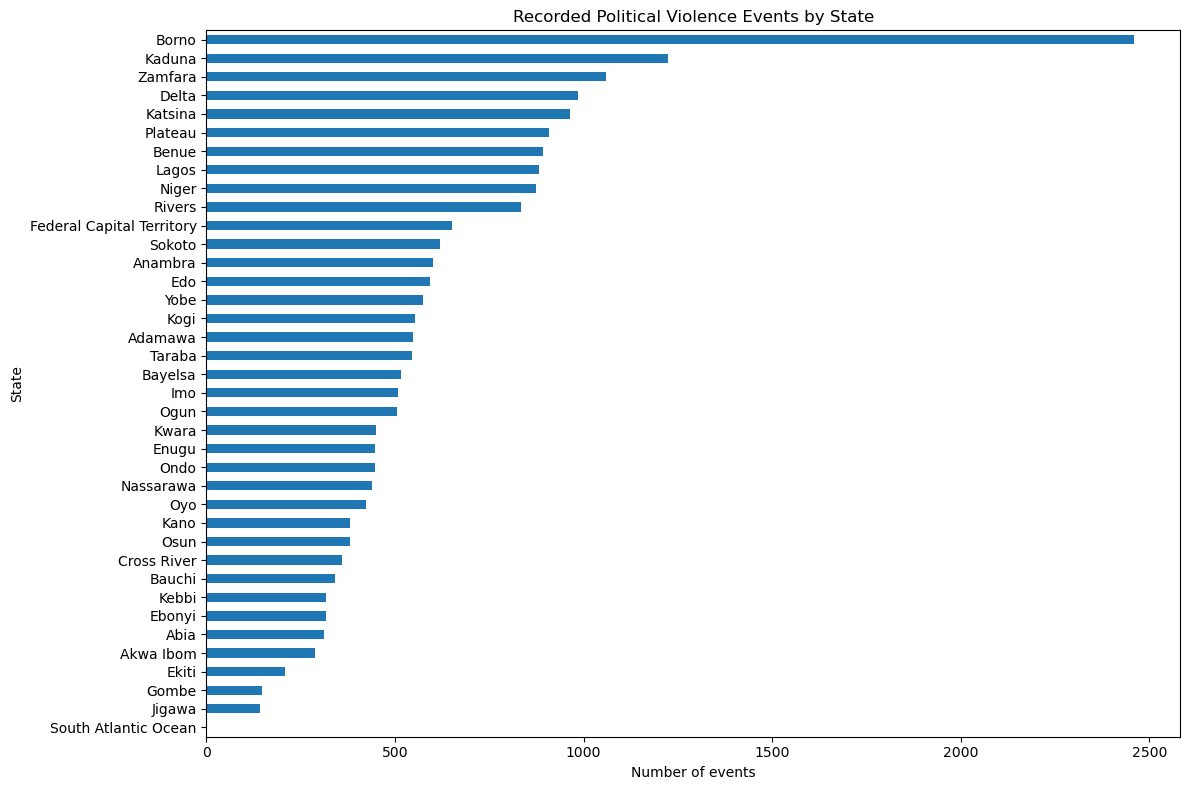

In [325]:
state_events = (
    df.groupby("admin1")
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))
state_events.sort_values().plot(kind="barh")
plt.title("Recorded Political Violence Events by State")
plt.xlabel("Number of events")
plt.ylabel("State")
plt.tight_layout()
plt.show()

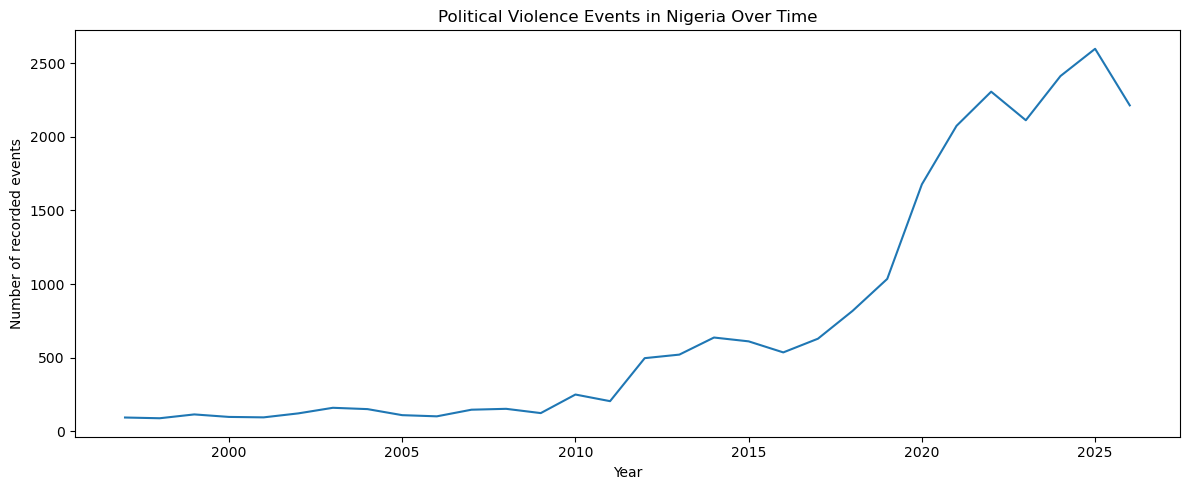

In [326]:
df["week"] = pd.to_datetime(
    df["week"],
    errors="coerce"
)

df["year"] = df["week"].dt.year
df["month"] = df["week"].dt.month

yearly_events = df.groupby("year").size()

plt.figure(figsize=(12, 5))
yearly_events.plot()
plt.title("Political Violence Events in Nigeria Over Time")
plt.xlabel("Year")
plt.ylabel("Number of recorded events")
plt.tight_layout()
plt.show()

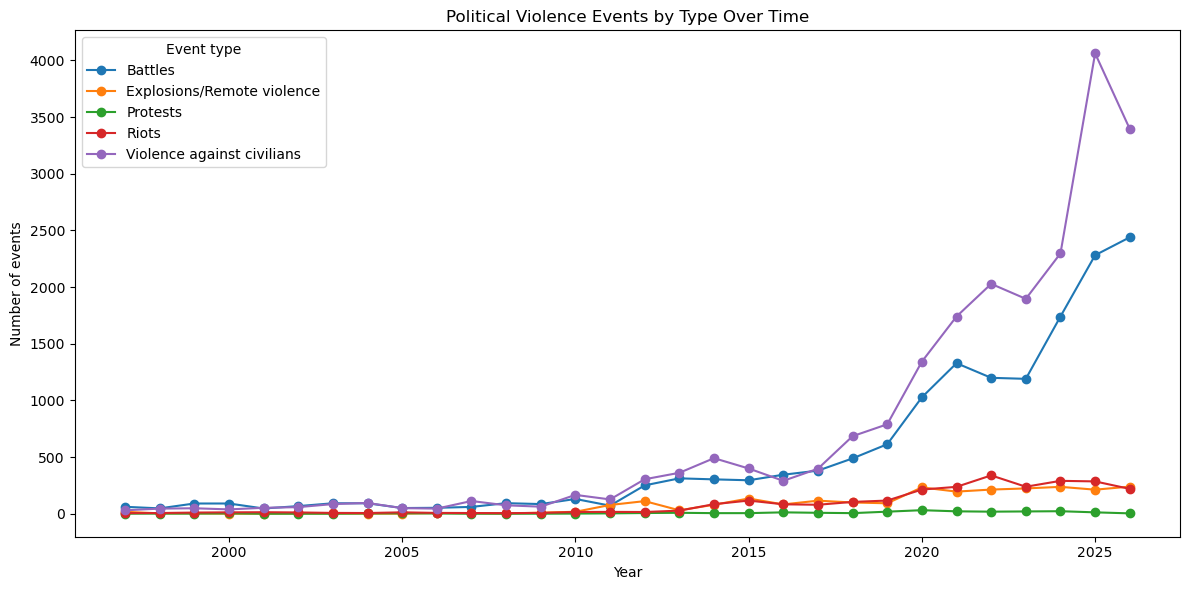

In [327]:
yearly_by_type = (
    df.groupby(["year", "event_type"])["events"]
    .sum()
    .unstack(fill_value=0)
)

ax = yearly_by_type.plot(figsize=(12, 6), marker="o")
ax.set_title("Political Violence Events by Type Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Number of events")
ax.legend(title="Event type")
plt.tight_layout()
plt.show()

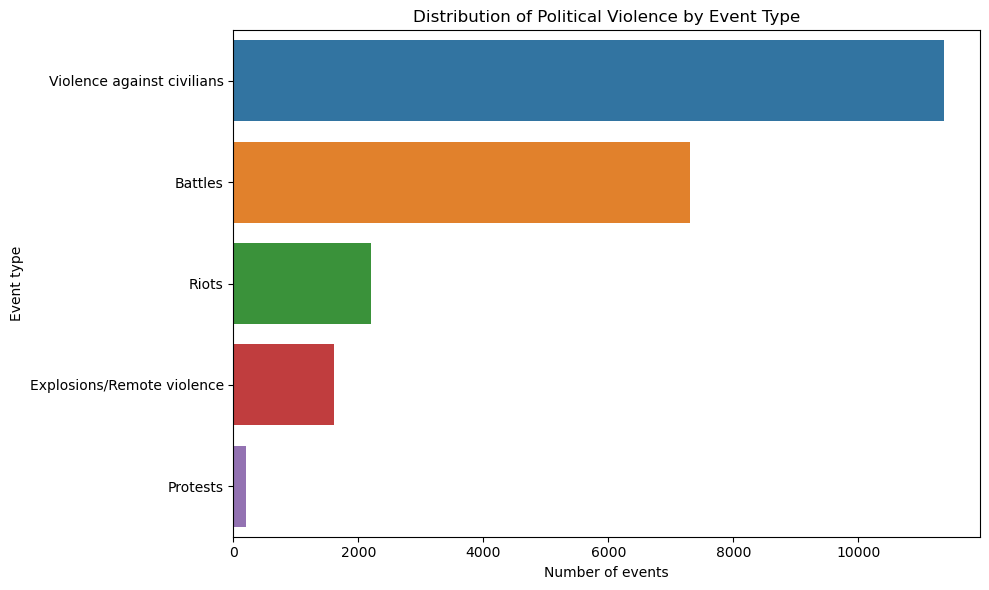

In [328]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y="event_type",
    order=df["event_type"].value_counts().index
)
plt.title("Distribution of Political Violence by Event Type")
plt.xlabel("Number of events")
plt.ylabel("Event type")
plt.tight_layout()
plt.show()

## 1.2  Target variable fatalities

In [329]:
df['fatalities'].describe()

count    22690.000000
mean         6.654473
std         30.032619
min          0.000000
25%          0.000000
50%          1.000000
75%          5.000000
max       2000.000000
Name: fatalities, dtype: float64

In [330]:
df.event_type

0                           Battles
1                           Battles
2                           Battles
3                           Battles
4        Explosions/Remote violence
                    ...            
33118                       Battles
33119    Violence against civilians
33120                       Battles
33122                       Battles
33124    Violence against civilians
Name: event_type, Length: 22690, dtype: object

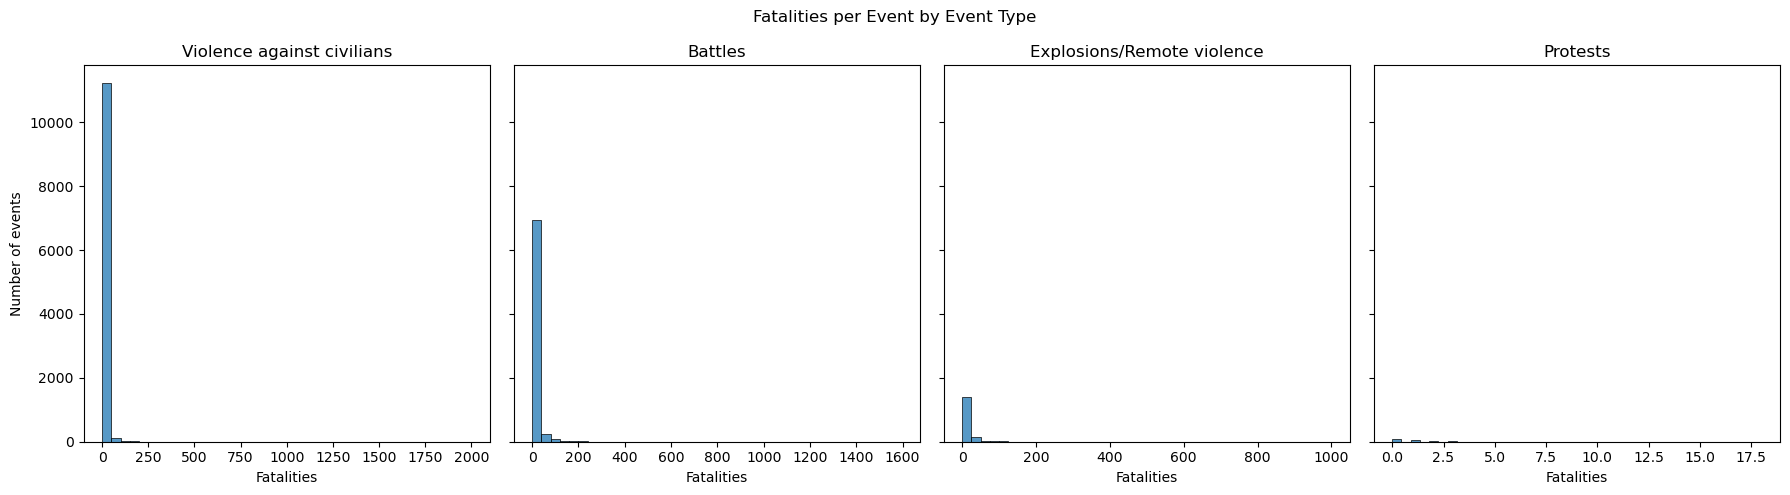

In [331]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
events = ["Violence against civilians", "Battles", "Explosions/Remote violence", "Protests", "Riots"]

for ax, event_type in zip(axes, events):
    sns.histplot(
        data=df[df["event_type"] == event_type],
        x="fatalities",
        bins=40,
        ax=ax
    )
    ax.set_title(event_type)
    ax.set_xlabel("Fatalities")
    ax.set_ylabel("Number of events")

fig.suptitle("Fatalities per Event by Event Type")
plt.tight_layout()
plt.show()

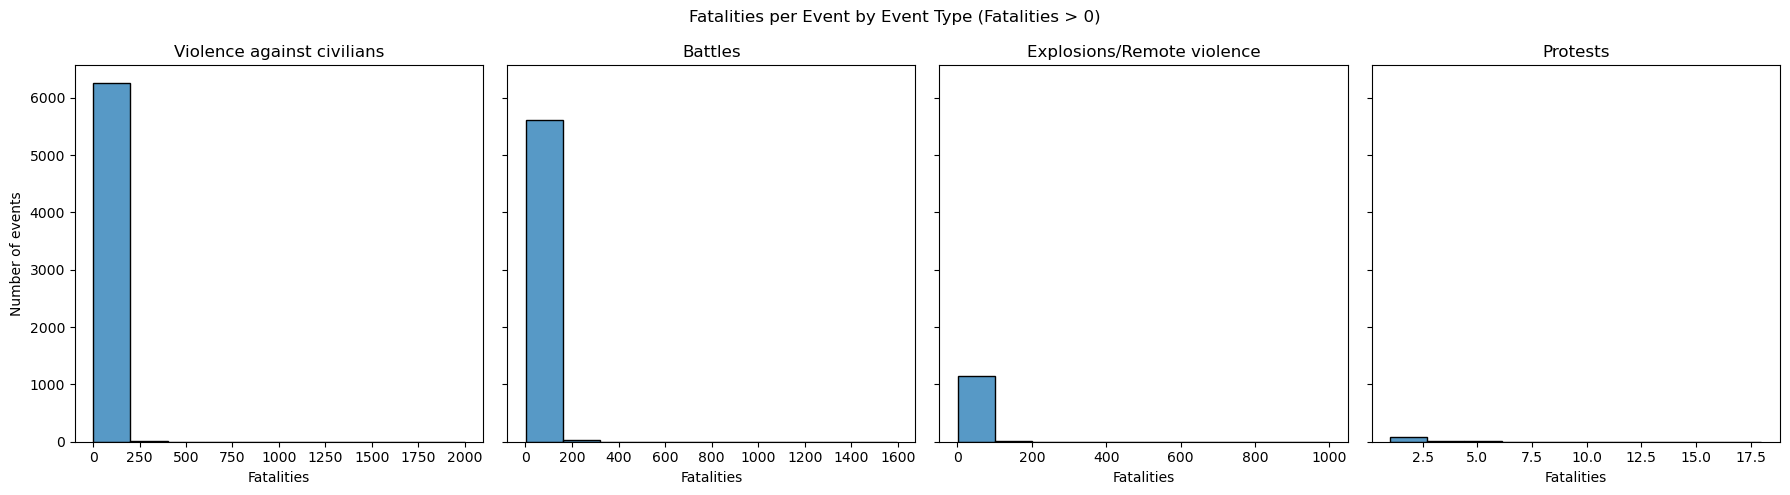

In [332]:
df_subset = df[df["fatalities"] > 0]

## look at it for non-zero counts fatalities
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)

for ax, event_type in zip(axes, events):
    sns.histplot(
        data=df_subset[df_subset["event_type"] == event_type],
        x="fatalities",
        bins=10,
        ax=ax
    )
    ax.set_title(event_type)
    ax.set_xlabel("Fatalities")
    ax.set_ylabel("Number of events")

fig.suptitle("Fatalities per Event by Event Type (Fatalities > 0)")
plt.tight_layout()
plt.show()

#heavily zeroinflated.


## 1.3 Feature engineering data prep

In [333]:
## election year count as a feature to add and construct.
election_years = [1999, 2003, 2007, 2011, 2015, 2019, 2023]

In [334]:
df.dtypes

week                   datetime64[ns]
region                         object
country                        object
admin1                         object
event_type                     object
sub_event_type                 object
events                          int64
fatalities                      int64
population_exposure            object
disorder_type                  object
centroid_latitude             float64
centroid_longitude            float64
year                            int32
month                           int32
dtype: object

In [335]:
# Extract year from event date
df['week'] = pd.to_datetime(df['week'])
df['year'] = df['week'].dt.year

# Define Nigerian national election years
election_years = [1999, 2003, 2007, 2011, 2015, 2019, 2023]

# Create dummy variable
df["is_election_year"] = df["year"].isin(election_years).astype(int)

In [336]:
df.head()

,week,region,country,admin1,event_type,sub_event_type,events,fatalities,population_exposure,disorder_type,centroid_latitude,centroid_longitude,year,month,is_election_year
0,1997-01-04,Western Africa,Nigeria,Bayelsa,Battles,Armed clash,1,1,0,Political violence,4.825,5.959,1997,1,0
1,1997-01-04,Western Africa,Nigeria,Cross River,Battles,Armed clash,1,1,0,Political violence,5.791,8.414,1997,1,0
2,1997-01-04,Western Africa,Nigeria,Delta,Battles,Armed clash,1,3,0,Political violence,5.760,6.327,1997,1,0
3,1997-01-04,Western Africa,Nigeria,Kogi,Battles,Armed clash,1,3,0,Political violence,7.621,6.854,1997,1,0
4,1997-01-04,Western Africa,Nigeria,Lagos,Explosions/Remote violence,Remote explosive/landmine/IED,1,2,0,Political violence,6.491,3.785,1997,1,0


In [337]:
# Count events by election-year status
df["is_election_year"].value_counts()

# Compare event counts by year
df.groupby("year")["is_election_year"].first()

year
1997    0
1998    0
1999    1
2000    0
2001    0
2002    0
2003    1
2004    0
2005    0
2006    0
2007    1
2008    0
2009    0
2010    0
2011    1
2012    0
2013    0
2014    0
2015    1
2016    0
2017    0
2018    0
2019    1
2020    0
2021    0
2022    0
2023    1
2024    0
2025    0
2026    0
Name: is_election_year, dtype: int64

In [338]:
## data cleaning and standardization

In [339]:
# Check whether missingness is linked to specific event types
exposure_by_type = df.groupby('event_type')['population_exposure'].apply(
    lambda x: f"{x.notna().sum()} / {len(x)} ({x.notna().mean()*100:.0f}% present)"
)
print('POPULATION_EXPOSURE availability by event type:')
print(exposure_by_type.to_string())


POPULATION_EXPOSURE availability by event type:
event_type
Battles                         7310 / 7310 (100% present)
Explosions/Remote violence      1602 / 1602 (100% present)
Protests                          198 / 198 (100% present)
Riots                           2205 / 2205 (100% present)
Violence against civilians    11375 / 11375 (100% present)


In [340]:
#convernt population_exposure to int

df['population_exposure'] = (
    df['population_exposure']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df['population_exposure'] = pd.to_numeric(df['population_exposure'], errors='coerce')

In [341]:
# feature engineering

# feature engineering
df['month'] = df['week'].dt.month
df['quarter'] = df['week'].dt.quarter
df['week_of_year'] = df['week'].dt.isocalendar().week.astype(int)


#is in election years 

#log transformers
df['log_population_exposure'] = np.log1p(df['population_exposure'])

#sort before lag features

df = df.sort_values(by=['admin1', 'week']).reset_index(drop=True)



In [342]:
#creating rolling windows

weekly_agg = df.groupby(['admin1', 'week'])[["events","fatalities"]].sum().reset_index()
weekly_agg.head(5)

,admin1,week,events,fatalities
0,Abia,1998-11-07,1,5
1,Abia,2000-02-26,3,452
2,Abia,2000-05-20,1,2
3,Abia,2000-07-29,1,0
4,Abia,2002-08-24,1,0


In [343]:
df.dtypes

week                       datetime64[ns]
region                             object
country                            object
admin1                             object
event_type                         object
sub_event_type                     object
events                              int64
fatalities                          int64
population_exposure                 int64
disorder_type                      object
centroid_latitude                 float64
centroid_longitude                float64
year                                int32
month                               int32
is_election_year                    int64
quarter                             int32
week_of_year                        int64
log_population_exposure           float64
dtype: object

In [344]:
import re

def clean(c, prefix):
    return f"{prefix}_{re.sub(r'[^a-z0-9]+', '_', str(c).lower()).strip('_')}"

# Weekly totals
weekly_agg = df.groupby(['admin1', 'week'])[["events", "fatalities","population_exposure"]].sum()

# Weekly event counts by event type and sub-event type
et = (df.groupby(['admin1', 'week', 'event_type'])['events'].sum()
        .unstack(fill_value=0))
et.columns = [clean(c, 'et') for c in et.columns]

sub = (df.groupby(['admin1', 'week', 'sub_event_type'])['events'].sum()
         .unstack(fill_value=0))
sub.columns = [clean(c, 'set') for c in sub.columns]

weekly_agg = weekly_agg.join(et).join(sub).reset_index()
weekly_agg.head(5)


# Standardise data types
weekly_agg['week'] = pd.to_datetime(weekly_agg['week']).dt.normalize()
weekly_agg['admin1'] = weekly_agg['admin1'].astype(str).str.strip()

# Drop non-state rows BEFORE building the grid
weekly_agg = weekly_agg[weekly_agg['admin1'] != 'South Atlantic Ocean'].copy()

# Check uniqueness BEFORE creating the grid
print("Rows after aggregation:", len(weekly_agg))
print("Duplicate admin1-week combinations:",
      weekly_agg.duplicated(['admin1', 'week']).sum())

# Create complete weekly grid
all_weeks = pd.date_range(
    weekly_agg['week'].min(),
    weekly_agg['week'].max(),
    freq='W-SAT'
)

admin1_list = weekly_agg['admin1'].unique()

panel_index = pd.MultiIndex.from_product(
    [admin1_list, all_weeks],
    names=['admin1', 'week']
)

# Reindex the aggregated data (type columns are zero-filled too)
panel = (
    weekly_agg.set_index(['admin1', 'week'])
              .reindex(panel_index, fill_value=0)
              .reset_index()
              .sort_values(['admin1', 'week'])
              .reset_index(drop=True)
)

# Year and month, derived AFTER the grid so empty weeks get them too
panel['year'] = panel['week'].dt.year
panel['month'] = panel['week'].dt.month
panel['is_election_year'] = (
    panel['week'].dt.year.isin(election_years)
).astype(int)

# Verify
print("\nPanel rows:", len(panel))
print("Expected rows:", len(admin1_list) * len(all_weeks))
print("Duplicate combinations:",
      panel.duplicated(['admin1', 'week']).sum())

et_cols  = [c for c in panel.columns if c.startswith('et_')]
set_cols = [c for c in panel.columns if c.startswith('set_')]
print("Event types:", len(et_cols), "| Sub-event types:", len(set_cols))

Rows after aggregation: 13952
Duplicate admin1-week combinations: 0

Panel rows: 57535
Expected rows: 57535
Duplicate combinations: 0
Event types: 5 | Sub-event types: 13


In [345]:
panel

,admin1,week,events,fatalities,population_exposure,et_battles,et_explosions_remote_violence,et_protests,et_riots,et_violence_against_civilians,...,set_grenade,set_mob_violence,set_non_state_actor_overtakes_territory,set_remote_explosive_landmine_ied,set_sexual_violence,set_shelling_artillery_missile_attack,set_suicide_bomb,year,month,is_election_year
0,Abia,1997-01-04,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1997,1,0
1,Abia,1997-01-11,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1997,1,0
2,Abia,1997-01-18,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1997,1,0
3,Abia,1997-01-25,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1997,1,0
4,Abia,1997-02-01,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1997,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57530,Zamfara,2026-09-19,11,17,722892,4,0,0,0,7,...,0,0,0,0,0,0,0,2026,9,0
57531,Zamfara,2026-09-26,18,18,206380,7,0,0,0,11,...,0,0,0,0,0,0,0,2026,9,0
57532,Zamfara,2026-10-03,19,40,6334,9,0,0,0,10,...,0,0,0,0,0,0,0,2026,10,0
57533,Zamfara,2026-10-10,23,33,21789,4,1,0,0,18,...,0,0,0,0,0,0,0,2026,10,0


In [346]:
# Lagged features
lag_cols = ['events', 'fatalities', 'population_exposure']
g = panel.groupby('admin1')

for col in lag_cols:
    panel[f'{col}_lag_w1'] = g[col].shift(1)

    for w in (4, 12):
        panel[f'{col}_lag_w{w}'] = g[col].transform(
            lambda s: s.shift(1).rolling(w, min_periods=1).sum()
        )

lags = [
    f'{c}_lag_w{w}'
    for c in lag_cols
    for w in (1, 4, 12)
]

panel[lags] = panel[lags].fillna(0)

# Log transformations
for c in lags:
    panel[c + '_log'] = np.log1p(panel[c])

# Targets
panel['dummy_conflict'] = (panel['fatalities'] >= 5).astype(int)  # arbitrary; UCDP uses 25 battle-related deaths for a conflict
panel['dummy_fat'] = (panel['fatalities'] >= 1).astype(int)

# Same-week exposure (EDA only, NOT a model feature)
panel['population_exposure_log'] = np.log1p(panel['population_exposure'])

# Model features: lagged versions only
feature_cols = [f'{c}_log' for c in lags] + ['is_election_year', 'month']


In [347]:
for target in ['dummy_conflict', 'dummy_fat']:
    print(panel[target].value_counts(normalize=True).round(3))

dummy_conflict
0    0.919
1    0.081
Name: proportion, dtype: float64
dummy_fat
0    0.823
1    0.177
Name: proportion, dtype: float64


In [348]:
print("Panel rows:", len(panel))

print(
    "Duplicate admin1-week combinations:",
    panel.duplicated(subset=['admin1', 'week']).sum()
)

print("Unique admin1:", panel['admin1'].nunique())
print("Unique weeks:", panel['week'].nunique())

Panel rows: 57535
Duplicate admin1-week combinations: 0
Unique admin1: 37
Unique weeks: 1555


In [349]:
# Number of admin1-weeks in original data
print("Original observed admin1-weeks:", len(weekly_agg))

# Number of admin1-weeks in complete panel
print("Complete panel admin1-weeks:", len(panel))

# Number of admin1-weeks added by reindexing
print("Weeks added:", len(panel) - len(weekly_agg))

# Number of zero-fatality observations in panel
print("Zero-fatality weeks:", (panel['fatalities'] == 0).sum())

# Number of positive-fatality observations
print("Positive-fatality weeks:", (panel['fatalities'] > 0).sum())

Original observed admin1-weeks:

 13952
Complete panel admin1-weeks: 57535
Weeks added: 43583
Zero-fatality weeks: 47328
Positive-fatality weeks: 10207


In [350]:
panel = panel.sort_values(['admin1', 'week']).copy()

panel['zero_fatalities'] = (panel['fatalities'] == 0).astype(int)

# Consecutive zero-fatality weeks per admin1
panel['zero_group'] = (
    panel.groupby('admin1')['zero_fatalities']
    .transform(lambda s: s.ne(s.shift()).cumsum())
)

zero_runs = (
    panel[panel['zero_fatalities'] == 1]
    .groupby(['admin1', 'zero_group'])
    .agg(
        start_week=('week', 'min'),
        end_week=('week', 'max'),
        consecutive_zero_weeks=('week', 'size')
    )
    .reset_index()
)

print(
    zero_runs.sort_values('consecutive_zero_weeks', ascending=False)
    .head(20)
)

           admin1  zero_group start_week   end_week  consecutive_zero_weeks
2547      Katsina           5 1998-01-31 2005-09-10                     398
3722         Osun          45 2001-12-01 2009-07-04                     397
4449       Taraba          19 2003-02-08 2010-07-03                     387
1052  Cross River          16 2003-03-29 2009-12-19                     352
4772      Zamfara           9 2003-11-15 2010-07-31                     351
2039        Gombe           7 2003-08-09 2010-01-30                     339
2682         Kogi           2 1997-01-11 2003-05-24                     333
2109          Imo          11 2003-03-01 2008-11-08                     298
3            Abia           7 2000-05-27 2005-12-24                     292
1694        Ekiti          11 2007-09-29 2013-03-23                     287
2612        Kebbi           1 1997-01-04 2002-05-18                     281
3323        Niger           3 2000-11-25 2006-02-11                     273
103       Ad

Percentage of events with fatalities: 17.74%


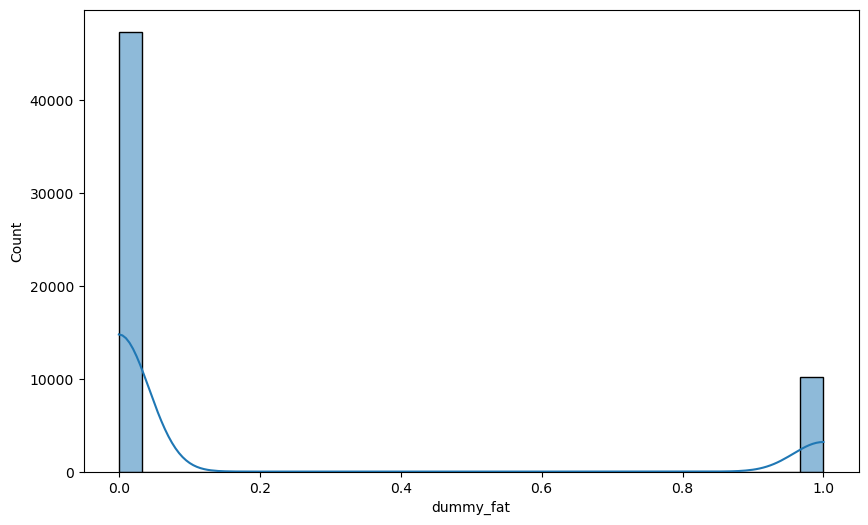

In [351]:
plt.figure(figsize=(10, 6))             
sns.histplot(data=panel, x='dummy_fat', bins=30, kde=True)  
#as a percentage print

print(f"Percentage of events with fatalities: {panel['dummy_fat'].mean() * 100:.2f}%")

In [352]:
#final dataset creation

print("Final dataset shape:", panel.shape)
print('Columns and null counts:')
for col in panel.columns:
    null_count = panel[col].isna().sum()
    null_pct   = null_count / len(df) * 100
    print(f'  {col:<30} dtype={str(panel[col].dtype):<12} nulls={null_count} ({null_pct:.1f}%)')

#save cleaned data
panel.to_csv('/Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/mid-term-project/data/cleaned_data.csv', index=False)

Final dataset shape: (57535, 49)
Columns and null counts:
  admin1                         dtype=object       nulls=0 (0.0%)
  week                           dtype=datetime64[ns] nulls=0 (0.0%)
  events                         dtype=int64        nulls=0 (0.0%)
  fatalities                     dtype=int64        nulls=0 (0.0%)
  population_exposure            dtype=int64        nulls=0 (0.0%)
  et_battles                     dtype=int64        nulls=0 (0.0%)
  et_explosions_remote_violence  dtype=int64        nulls=0 (0.0%)
  et_protests                    dtype=int64        nulls=0 (0.0%)
  et_riots                       dtype=int64        nulls=0 (0.0%)
  et_violence_against_civilians  dtype=int64        nulls=0 (0.0%)
  set_abduction_forced_disappearance dtype=int64        nulls=0 (0.0%)
  set_air_drone_strike           dtype=int64        nulls=0 (0.0%)
  set_armed_clash                dtype=int64        nulls=0 (0.0%)
  set_attack                     dtype=int64        nulls=0 (0.0%

In [353]:
panel

,admin1,week,events,fatalities,population_exposure,et_battles,et_explosions_remote_violence,et_protests,et_riots,et_violence_against_civilians,...,fatalities_lag_w4_log,fatalities_lag_w12_log,population_exposure_lag_w1_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,dummy_conflict,dummy_fat,population_exposure_log,zero_fatalities,zero_group
0,Abia,1997-01-04,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,0.000000,1,1
1,Abia,1997-01-11,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,0.000000,1,1
2,Abia,1997-01-18,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,0.000000,1,1
3,Abia,1997-01-25,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,0.000000,1,1
4,Abia,1997-02-01,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0,0,0.000000,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57530,Zamfara,2026-09-19,11,17,722892,4,0,0,0,7,...,5.068904,6.216606,13.143884,14.114839,15.488569,1,1,13.491016,0,160
57531,Zamfara,2026-09-26,18,18,206380,7,0,0,0,11,...,4.787492,6.230481,13.491016,14.353976,15.562718,1,1,12.237479,0,160
57532,Zamfara,2026-10-03,19,40,6334,9,0,0,0,10,...,4.574711,6.129050,12.237479,14.370112,15.499208,1,1,8.753845,0,160
57533,Zamfara,2026-10-10,23,33,21789,4,1,0,0,18,...,4.682131,6.184149,8.753845,14.184646,15.315964,1,1,9.989206,0,160


# 2. Explatory data analysis (EDA) and visualization

In [354]:
df = panel
#summary stats of target variable- event and fatalities
print(df['events'].describe())
df['fatalities'].describe()

count    57535.000000
mean         0.731746
std          2.334410
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         54.000000
Name: events, dtype: float64


count    57535.000000
mean         2.624281
std         21.019911
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       2110.000000
Name: fatalities, dtype: float64

In [355]:
cols = ['events', 'fatalities']   # replace with your two columns

for c in cols:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < lower) | (df[c] > upper)).sum()
    print(f"{c}: bounds {lower:.2f} to {upper:.2f}, {n_out} outliers ({n_out/len(df):.1%})")


events: bounds 0.00 to 0.00, 13952 outliers (24.2%)
fatalities: bounds 0.00 to 0.00, 10207 outliers (17.7%)


In [356]:
for c in cols:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    df[f'{c}_outlier'] = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)

# Rows that are outliers in either column
df[df[[f'{c}_outlier' for c in cols]].any(axis=1)]

# Rows that are outliers in both
df[df[[f'{c}_outlier' for c in cols]].all(axis=1)]

,admin1,week,events,fatalities,population_exposure,et_battles,et_explosions_remote_violence,et_protests,et_riots,et_violence_against_civilians,...,population_exposure_lag_w1_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,dummy_conflict,dummy_fat,population_exposure_log,zero_fatalities,zero_group,events_outlier,fatalities_outlier
96,Abia,1998-11-07,1,5,0,0,0,0,1,0,...,0.000000,0.000000,0.000000,1,1,0.000000,0,2,True,True
164,Abia,2000-02-26,3,452,0,3,0,0,0,0,...,0.000000,0.000000,0.000000,1,1,0.000000,0,4,True,True
176,Abia,2000-05-20,1,2,0,1,0,0,0,0,...,0.000000,0.000000,0.000000,0,1,0.000000,0,6,True,True
469,Abia,2005-12-31,1,5,0,1,0,0,0,0,...,0.000000,0.000000,0.000000,1,1,0.000000,0,8,True,True
507,Abia,2006-09-23,1,1,0,0,0,0,0,1,...,0.000000,0.000000,0.000000,0,1,0.000000,0,10,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57530,Zamfara,2026-09-19,11,17,722892,4,0,0,0,7,...,13.143884,14.114839,15.488569,1,1,13.491016,0,160,True,True
57531,Zamfara,2026-09-26,18,18,206380,7,0,0,0,11,...,13.491016,14.353976,15.562718,1,1,12.237479,0,160,True,True
57532,Zamfara,2026-10-03,19,40,6334,9,0,0,0,10,...,12.237479,14.370112,15.499208,1,1,8.753845,0,160,True,True
57533,Zamfara,2026-10-10,23,33,21789,4,1,0,0,18,...,8.753845,14.184646,15.315964,1,1,9.989206,0,160,True,True


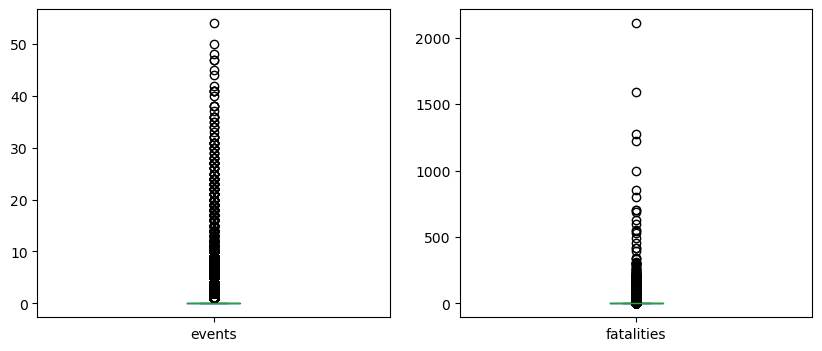

In [357]:
df[cols].plot(kind='box', subplots=True, layout=(1, 2), figsize=(10, 4))
plt.show()

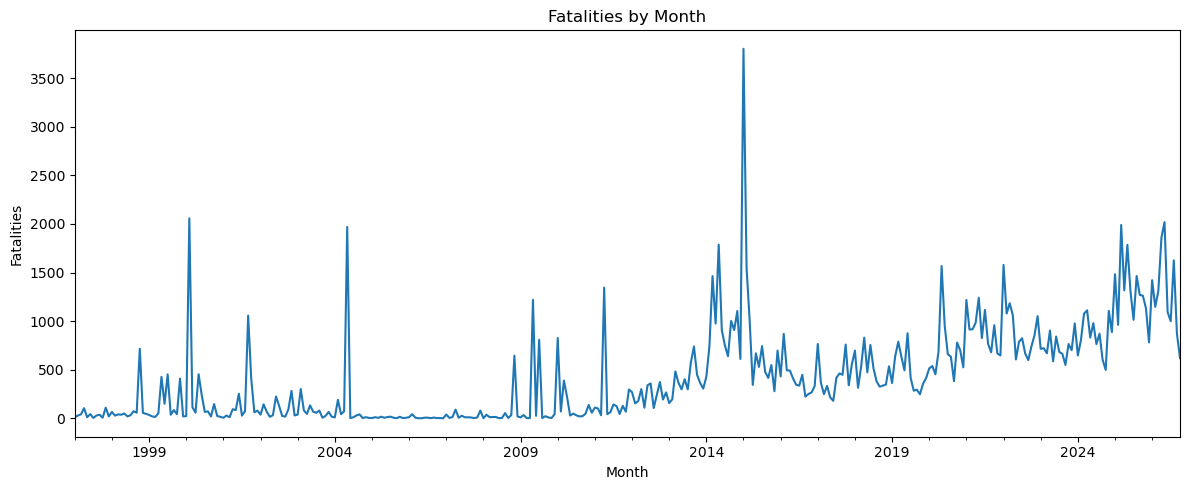

In [358]:
#make one with nonzero fatalities

nonzero =df[df['fatalities'] > 0]

# Sum nonzero fatalities by calendar month
monthly_fatalities = (
    nonzero.groupby(nonzero["week"].dt.to_period("M"))["fatalities"]
    .sum()
)

monthly_fatalities.index = monthly_fatalities.index.to_timestamp()

monthly_fatalities.plot(kind="line", figsize=(12, 5), title="Fatalities by Month")
plt.xlabel("Month")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

## 2.1 context
- what is the big spike in 2015/2016 where are the spikes happening 

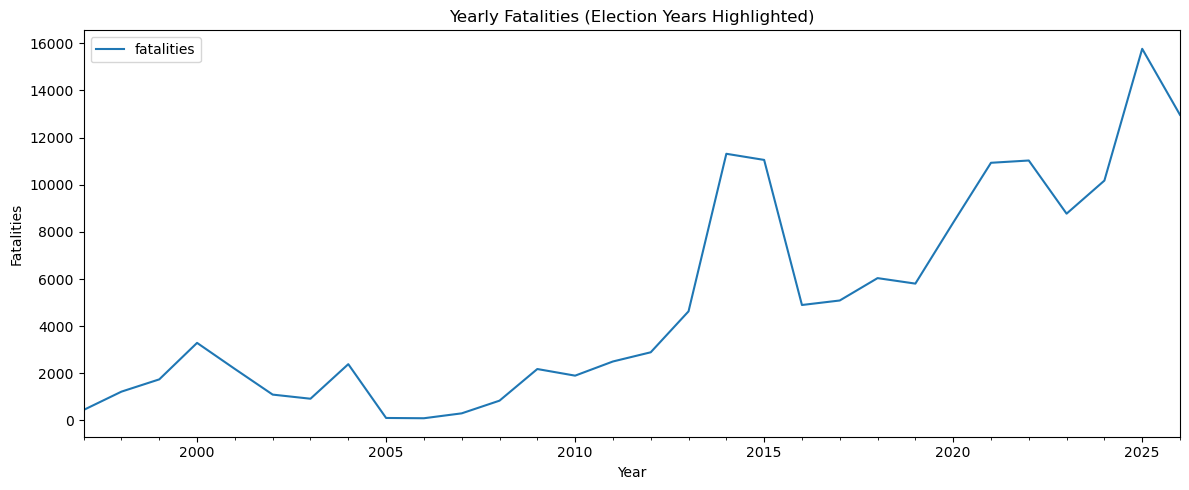

In [359]:

# Sum nonzero fatalities by calendar month
yearly_fatalities = (
    nonzero.groupby(nonzero["week"].dt.to_period("Y"))["fatalities"]
    .sum()
)
ax = yearly_fatalities.plot(
    kind="line",
    figsize=(12, 5),
    title="Yearly Fatalities (Election Years Highlighted)"
)


ax.set_xlabel("Year")
ax.set_ylabel("Fatalities")
ax.legend()
plt.tight_layout()
plt.show()

,Count,Percentage
Zero fatalities,47328,82.26
Nonzero fatalities,10207,17.74


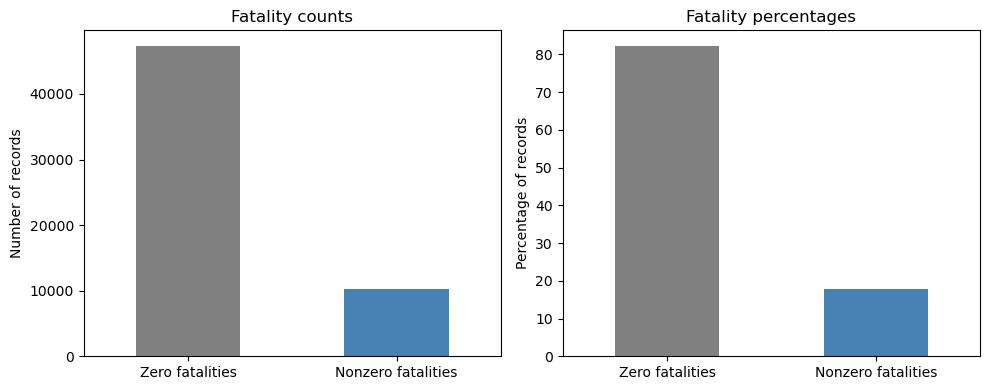

In [360]:
fatalities_nonzero = df.loc[df["fatalities"] > 0, "fatalities"]

fatality_summary = pd.DataFrame({
    "Count": [
        (df["fatalities"] == 0).sum(),
        (df["fatalities"] > 0).sum()
    ]
}, index=["Zero fatalities", "Nonzero fatalities"])

fatality_summary["Percentage"] = (
    fatality_summary["Count"] / len(df) * 100
)

display(fatality_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

fatality_summary["Count"].plot(kind="bar", ax=axes[0], color=["gray", "steelblue"])
axes[0].set_title("Fatality counts")
axes[0].set_ylabel("Number of records")
axes[0].tick_params(axis="x", rotation=0)

fatality_summary["Percentage"].plot(kind="bar", ax=axes[1], color=["gray", "steelblue"])
axes[1].set_title("Fatality percentages")
axes[1].set_ylabel("Percentage of records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

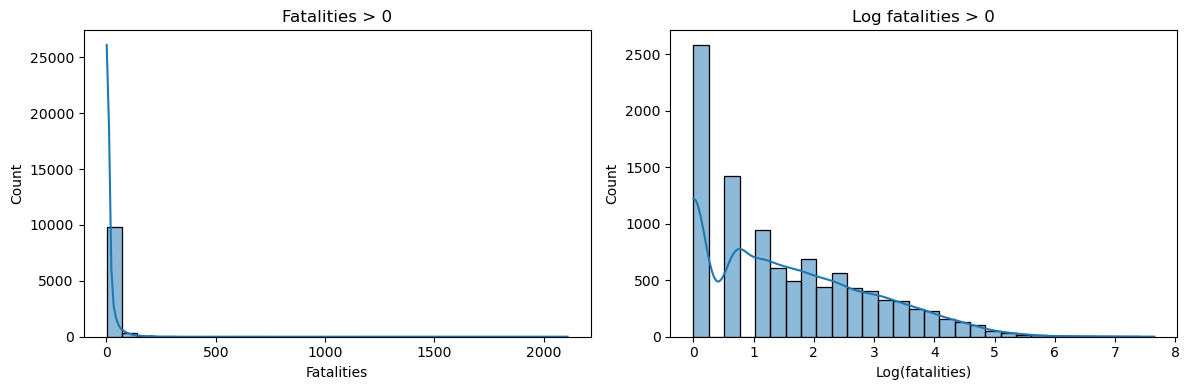

In [361]:
fatalities_nonzero = df.loc[df["fatalities"] > 0, "fatalities"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(fatalities_nonzero, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Fatalities > 0")
axes[0].set_xlabel("Fatalities")

sns.histplot(np.log(fatalities_nonzero), bins=30, kde=True, ax=axes[1])
axes[1].set_title("Log fatalities > 0")
axes[1].set_xlabel("Log(fatalities)")

plt.tight_layout()
plt.show()

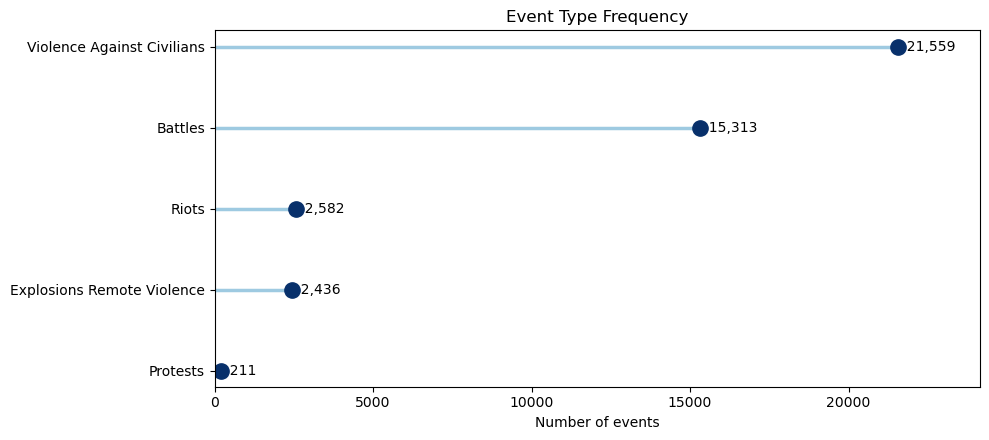

In [362]:
#viz of its distribution

#fatalities by event type 

import matplotlib.pyplot as plt

# Total events per event type (columns are now et_*)
event_counts = panel[et_cols].sum().sort_values()

# Tidy labels: "et_violence_against_civilians" -> "Violence Against Civilians"
event_counts.index = (event_counts.index
                      .str.replace('et_', '', regex=False)
                      .str.replace('_', ' ')
                      .str.title())

plt.figure(figsize=(10, 4.5))
plt.hlines(y=event_counts.index, xmin=0, xmax=event_counts.values,
           color='#9ecae1', linewidth=2.5)
plt.plot(event_counts.values, event_counts.index, 'o',
         markersize=11, color='#08306b')

for i, v in enumerate(event_counts.values):
    plt.text(v, i, f'  {v:,}', va='center', fontsize=10)

plt.title('Event Type Frequency')
plt.xlabel('Number of events')
plt.xlim(0, event_counts.max() * 1.12)
plt.tight_layout()
plt.show()

In [363]:
panel

,admin1,week,events,fatalities,population_exposure,et_battles,et_explosions_remote_violence,et_protests,et_riots,et_violence_against_civilians,...,population_exposure_lag_w1_log,population_exposure_lag_w4_log,population_exposure_lag_w12_log,dummy_conflict,dummy_fat,population_exposure_log,zero_fatalities,zero_group,events_outlier,fatalities_outlier
0,Abia,1997-01-04,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0,0,0.000000,1,1,False,False
1,Abia,1997-01-11,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0,0,0.000000,1,1,False,False
2,Abia,1997-01-18,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0,0,0.000000,1,1,False,False
3,Abia,1997-01-25,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0,0,0.000000,1,1,False,False
4,Abia,1997-02-01,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0,0,0.000000,1,1,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57530,Zamfara,2026-09-19,11,17,722892,4,0,0,0,7,...,13.143884,14.114839,15.488569,1,1,13.491016,0,160,True,True
57531,Zamfara,2026-09-26,18,18,206380,7,0,0,0,11,...,13.491016,14.353976,15.562718,1,1,12.237479,0,160,True,True
57532,Zamfara,2026-10-03,19,40,6334,9,0,0,0,10,...,12.237479,14.370112,15.499208,1,1,8.753845,0,160,True,True
57533,Zamfara,2026-10-10,23,33,21789,4,1,0,0,18,...,8.753845,14.184646,15.315964,1,1,9.989206,0,160,True,True


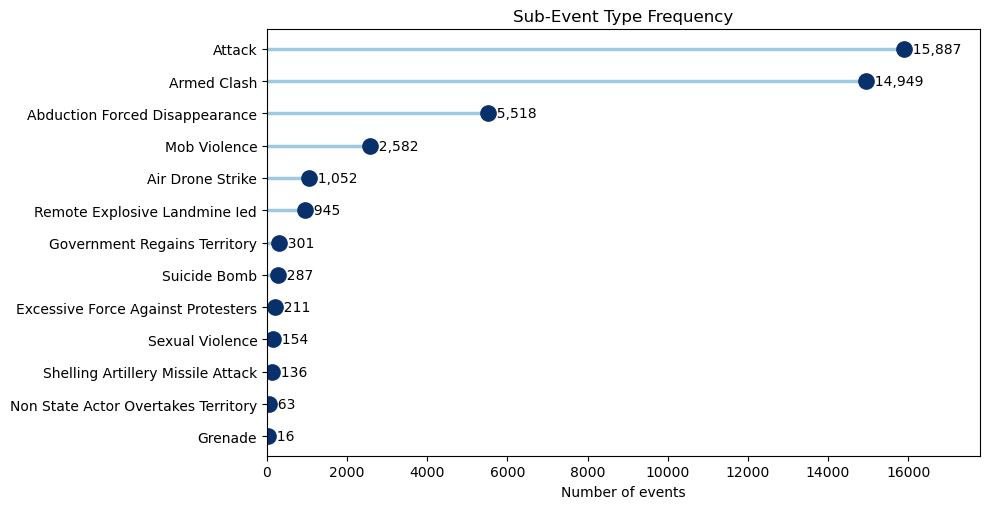

In [364]:


# Total events per sub-event type (columns are now set_*)
sub_event_counts = panel[set_cols].sum().sort_values()

# Tidy labels: "set_suicide_bomb" -> "Suicide Bomb"
sub_event_counts.index = (sub_event_counts.index
                          .str.replace('set_', '', regex=False)
                          .str.replace('_', ' ')
                          .str.title())

plt.figure(figsize=(10, max(4.5, 0.4 * len(sub_event_counts))))
plt.hlines(y=sub_event_counts.index, xmin=0, xmax=sub_event_counts.values,
           color='#9ecae1', linewidth=2.5)
plt.plot(sub_event_counts.values, sub_event_counts.index, 'o',
         markersize=11, color='#08306b')

for i, v in enumerate(sub_event_counts.values):
    plt.text(v, i, f'  {v:,}', va='center', fontsize=10)

plt.title('Sub-Event Type Frequency')
plt.xlabel('Number of events')
plt.xlim(0, sub_event_counts.max() * 1.12)
plt.tight_layout()
plt.show()

In [365]:
!pip install squarify 

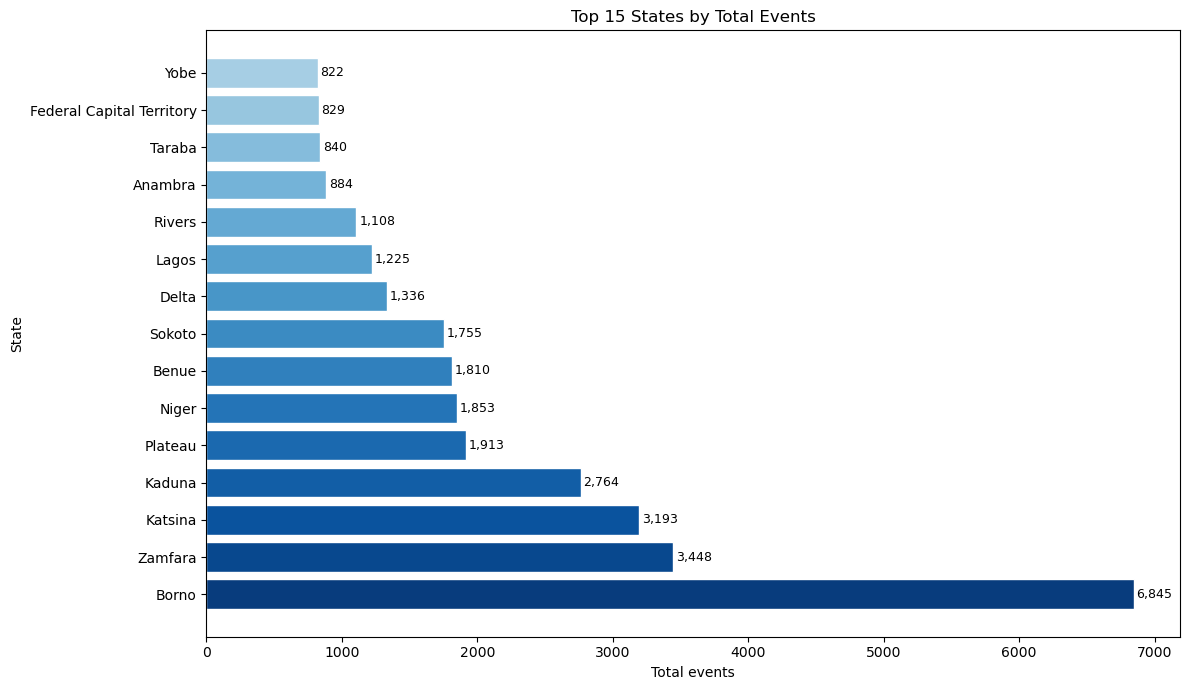

In [366]:
# Bar chart alternative to the treemap
top_events = df.groupby('admin1')['events'].sum().nlargest(15).sort_values()

colors = plt.cm.Blues(np.linspace(0.35, 0.95, len(top_events)))

plt.figure(figsize=(12, 7))
bars = plt.barh(
    top_events.index,
    top_events.values,
    color=colors,
    edgecolor='white'
)

plt.gca().invert_yaxis()
plt.title('Top 15 States by Total Events')
plt.xlabel('Total events')
plt.ylabel('State')
plt.tight_layout()

for bar, value in zip(bars, top_events.values):
    plt.text(
        value + 20,
        bar.get_y() + bar.get_height() / 2,
        f'{value:,}',
        va='center',
        fontsize=9
    )

plt.show()


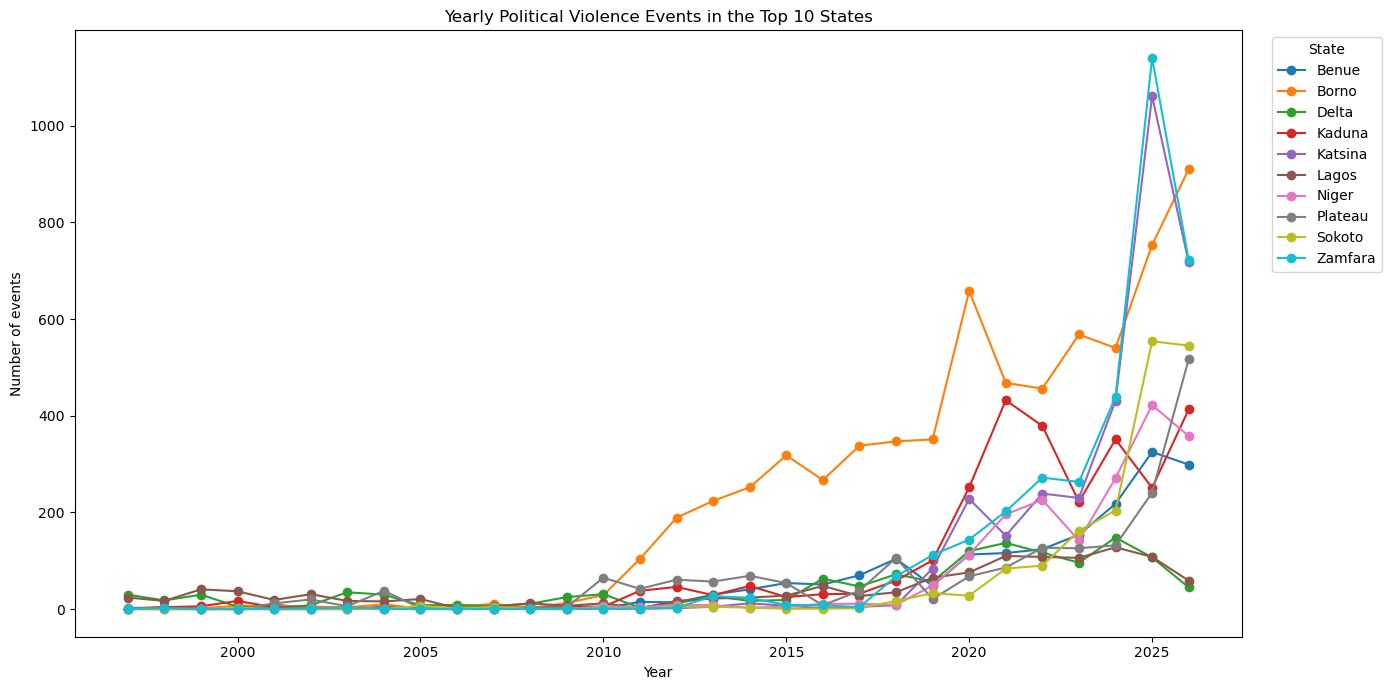

In [367]:
# Select the 10 states with the most events across the full period
top_10_states = (
    df.groupby("admin1")["events"]
    .sum()
    .nlargest(10)
    .index
)

# Sum events by year for those states
yearly_top_10 = (
    df[df["admin1"].isin(top_10_states)]
    .groupby(["year", "admin1"])["events"]
    .sum()
    .unstack(fill_value=0)
)

ax = yearly_top_10.plot(figsize=(14, 7), marker="o", linewidth=1.5)
ax.set_title("Yearly Political Violence Events in the Top 10 States")
ax.set_xlabel("Year")
ax.set_ylabel("Number of events")
ax.legend(title="State", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


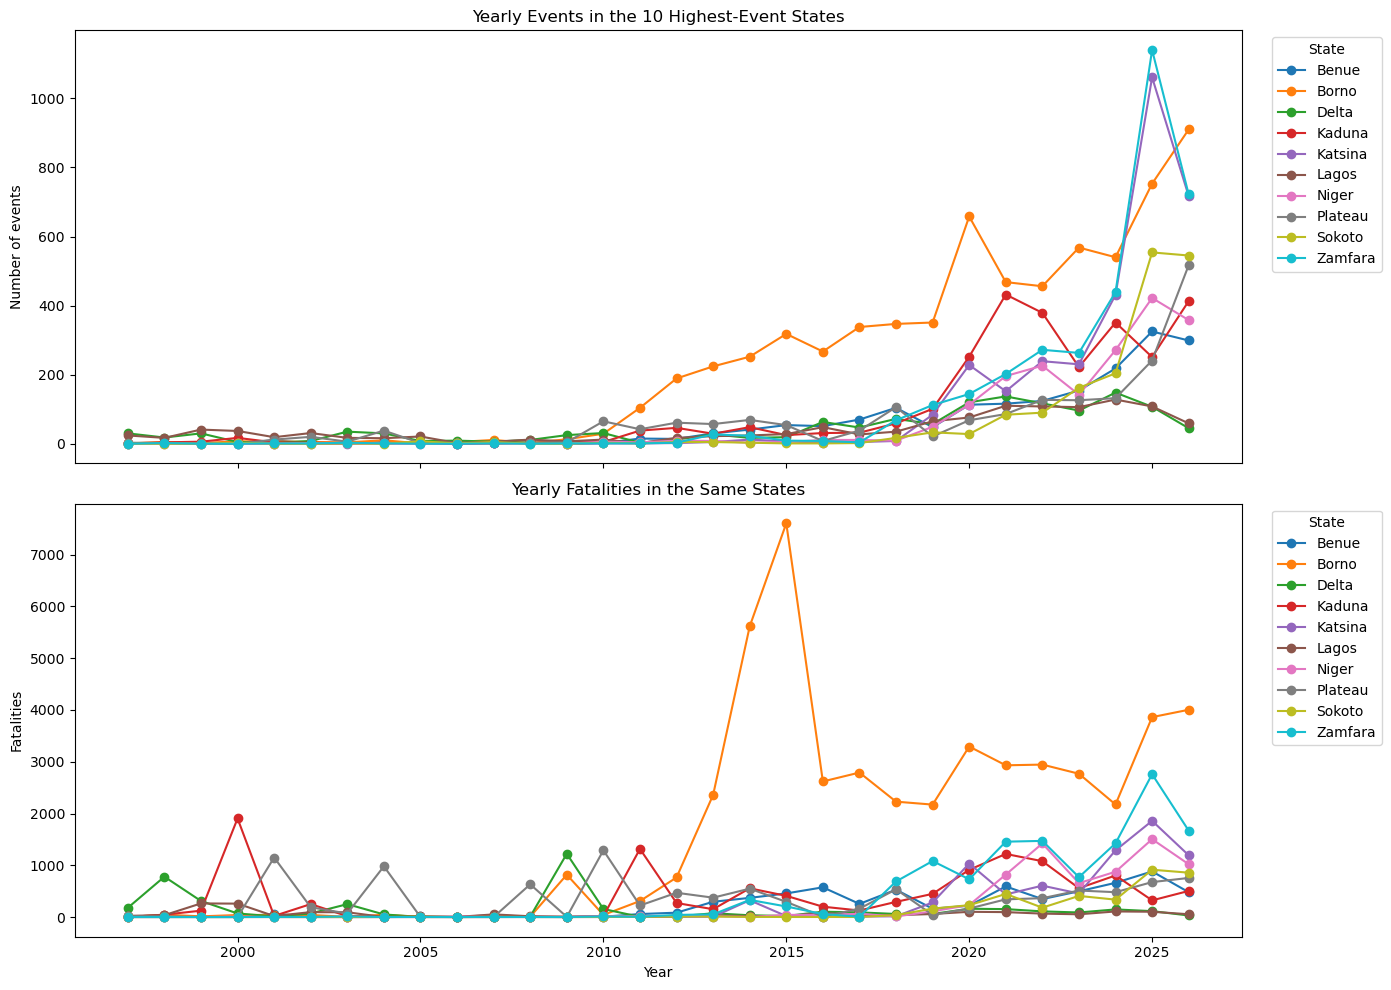

In [368]:
yearly_top_10_fatalities = (
    df[df["admin1"].isin(top_10_states)]
    .groupby(["year", "admin1"])["fatalities"]
    .sum()
    .unstack(fill_value=0)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

yearly_top_10.plot(ax=axes[0], marker="o", linewidth=1.5)
axes[0].set_title("Yearly Events in the 10 Highest-Event States")
axes[0].set_ylabel("Number of events")
axes[0].legend(title="State", bbox_to_anchor=(1.02, 1), loc="upper left")

yearly_top_10_fatalities.plot(ax=axes[1], marker="o", linewidth=1.5)
axes[1].set_title("Yearly Fatalities in the Same States")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Fatalities")
axes[1].legend(title="State", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()



## 2.2 shows deadly conflict is more in Borno state- conflict context here:

-  where is the conflict driven from?
- what type of conflict 
- which areas are urban vs rural areas

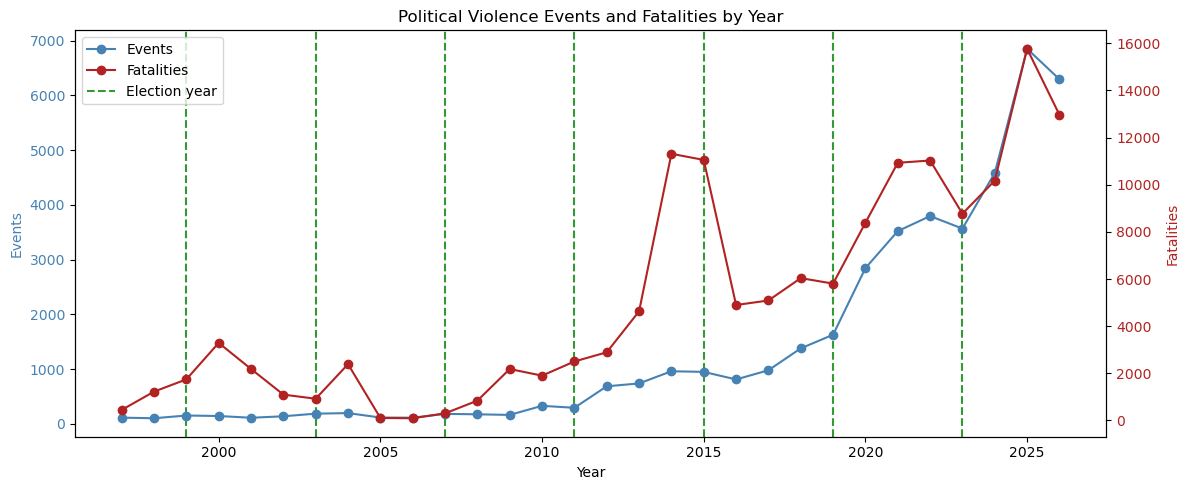

In [369]:
yearly_totals = df.groupby("year")[["events", "fatalities"]].sum()

election_mask = (
    df.groupby("year")["is_election_year"]
    .max()
    .reindex(yearly_totals.index)
    .fillna(0)
    .astype(bool)
)

fig, ax1 = plt.subplots(figsize=(12, 5))

line1, = ax1.plot(
    yearly_totals.index, yearly_totals["events"],
    color="steelblue", marker="o", label="Events"
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Events", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

ax2 = ax1.twinx()
line2, = ax2.plot(
    yearly_totals.index, yearly_totals["fatalities"],
    color="firebrick", marker="o", label="Fatalities"
)
ax2.set_ylabel("Fatalities", color="firebrick")
ax2.tick_params(axis="y", labelcolor="firebrick")

# Mark election years with dashed vertical lines
election_line = None
for year in yearly_totals.index[election_mask]:
    election_line = ax1.axvline(
        x=year, color="green", linestyle="--", linewidth=1.5,
        alpha=0.8, zorder=1,
        label="Election year" if election_line is None else "_nolegend_"
    )

ax1.set_title("Political Violence Events and Fatalities by Year")
ax1.legend(
    [line1, line2, election_line],
    ["Events", "Fatalities", "Election year"],
    loc="upper left"
)

fig.tight_layout()
plt.show()

In [370]:
df.dtypes

admin1                                             object
week                                       datetime64[ns]
events                                              int64
fatalities                                          int64
population_exposure                                 int64
et_battles                                          int64
et_explosions_remote_violence                       int64
et_protests                                         int64
et_riots                                            int64
et_violence_against_civilians                       int64
set_abduction_forced_disappearance                  int64
set_air_drone_strike                                int64
set_armed_clash                                     int64
set_attack                                          int64
set_excessive_force_against_protesters              int64
set_government_regains_territory                    int64
set_grenade                                         int64
set_mob_violen

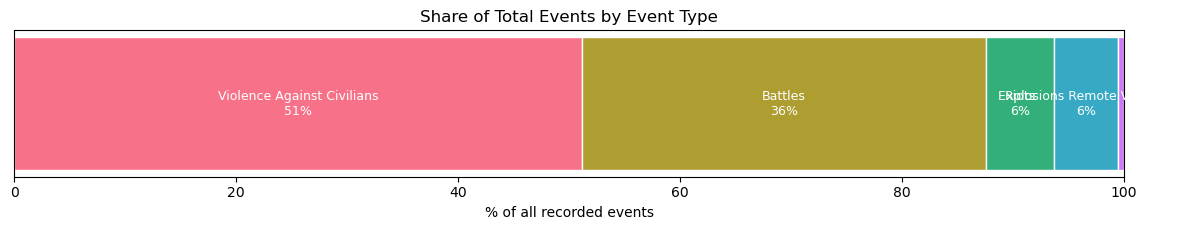

In [371]:
import matplotlib.pyplot as plt
import seaborn as sns

# Share of total events by event type (df is wide: one et_* column per type)
et_cols = [c for c in df.columns if c.startswith('et_')]

totals = df[et_cols].sum().sort_values(ascending=False)
totals.index = (totals.index.str.replace('et_', '', regex=False)
                            .str.replace('_', ' ').str.title())
pct = totals / totals.sum() * 100

# One colour per category, matched by name
palette = dict(zip(pct.index, sns.color_palette("husl", len(pct)).as_hex()))

fig, ax = plt.subplots(figsize=(12, 2.4))
left = 0
for name, p in pct.items():
    ax.barh(0, p, left=left, color=palette[name], edgecolor='white')
    if p > 4:
        ax.text(left + p/2, 0, f'{name}\n{p:.0f}%', ha='center', va='center',
                fontsize=9, color='white')
    left += p

ax.set_yticks([])
ax.set_xlim(0, 100)
ax.set_xlabel('% of all recorded events')
ax.set_title('Share of Total Events by Event Type')
plt.tight_layout()
plt.show()

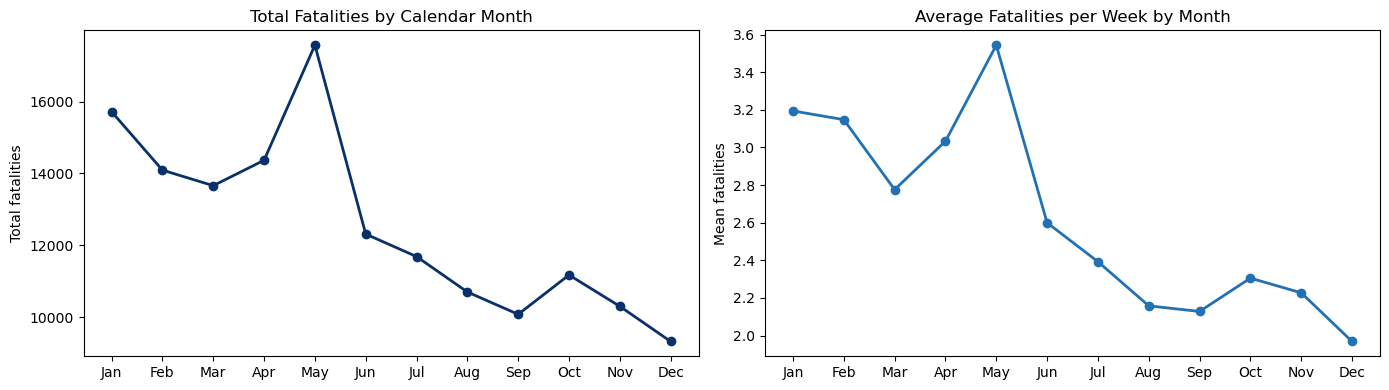

In [372]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

df['month'] = df['week'].dt.month

monthly = df.groupby('month').agg(
    total_fatalities=('fatalities', 'sum'),
    mean_fatalities=('fatalities', 'mean')
).reset_index()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(monthly['month'], monthly['total_fatalities'],
             marker='o', color='#08306b', linewidth=2)
axes[0].set_title('Total Fatalities by Calendar Month')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(month_names)
axes[0].set_ylabel('Total fatalities')

axes[1].plot(monthly['month'], monthly['mean_fatalities'],
             marker='o', color='#2171b5', linewidth=2)
axes[1].set_title('Average Fatalities per Week by Month')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_ylabel('Mean fatalities')

plt.tight_layout()
plt.show()

In [373]:
df.dtypes

admin1                                             object
week                                       datetime64[ns]
events                                              int64
fatalities                                          int64
population_exposure                                 int64
et_battles                                          int64
et_explosions_remote_violence                       int64
et_protests                                         int64
et_riots                                            int64
et_violence_against_civilians                       int64
set_abduction_forced_disappearance                  int64
set_air_drone_strike                                int64
set_armed_clash                                     int64
set_attack                                          int64
set_excessive_force_against_protesters              int64
set_government_regains_territory                    int64
set_grenade                                         int64
set_mob_violen

                    events  fatalities
is_election_year                      
0                 0.798183    2.722757
1                 0.515143    2.303221


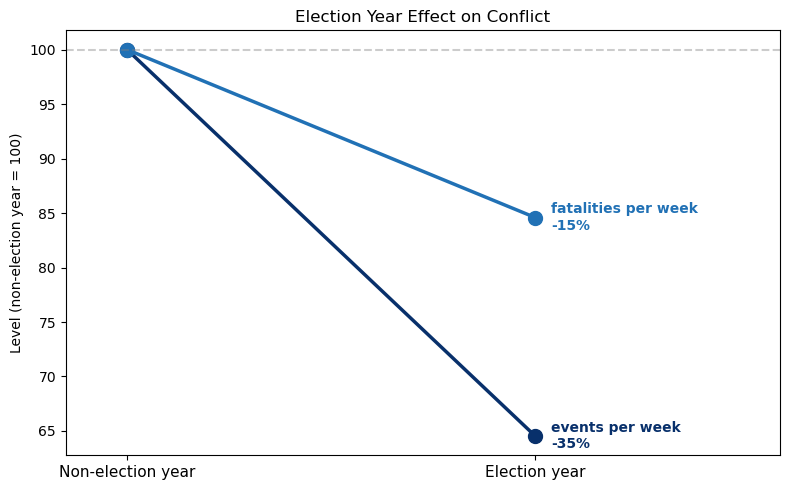

In [374]:
means = df.groupby('is_election_year')[['events', 'fatalities']].mean()
print(means)
normed = means / means.iloc[0] * 100   # first row (non-election year) = 100

fig, ax = plt.subplots(figsize=(8, 5))
styles = {'events': ('#08306b', 'events per week'),
          'fatalities': ('#2171b5', 'fatalities per week')}

for col, (color, label) in styles.items():
    y0, y1 = normed[col].iloc[0], normed[col].iloc[1]
    ax.plot([0, 1], [y0, y1], marker='o', markersize=10,
            color=color, linewidth=2.5, label=label)
    ax.text(1.04, y1, f'{label}\n{y1 - 100:+.0f}%', va='center',
            fontsize=10, color=color, fontweight='bold')

ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-election year', 'Election year'], fontsize=11)
ax.set_ylabel('Level (non-election year = 100)')
ax.axhline(100, color='gray', linestyle='--', alpha=0.4)
ax.set_xlim(-0.15, 1.6)
ax.set_title('Election Year Effect on Conflict')
plt.tight_layout()
plt.show()

In [375]:
df.columns

Index(['admin1', 'week', 'events', 'fatalities', 'population_exposure',
       'et_battles', 'et_explosions_remote_violence', 'et_protests',
       'et_riots', 'et_violence_against_civilians',
       'set_abduction_forced_disappearance', 'set_air_drone_strike',
       'set_armed_clash', 'set_attack',
       'set_excessive_force_against_protesters',
       'set_government_regains_territory', 'set_grenade', 'set_mob_violence',
       'set_non_state_actor_overtakes_territory',
       'set_remote_explosive_landmine_ied', 'set_sexual_violence',
       'set_shelling_artillery_missile_attack', 'set_suicide_bomb', 'year',
       'month', 'is_election_year', 'events_lag_w1', 'events_lag_w4',
       'events_lag_w12', 'fatalities_lag_w1', 'fatalities_lag_w4',
       'fatalities_lag_w12', 'population_exposure_lag_w1',
       'population_exposure_lag_w4', 'population_exposure_lag_w12',
       'events_lag_w1_log', 'events_lag_w4_log', 'events_lag_w12_log',
       'fatalities_lag_w1_log', 'fatalities

3.8.0 0.12.2
(10, 10)


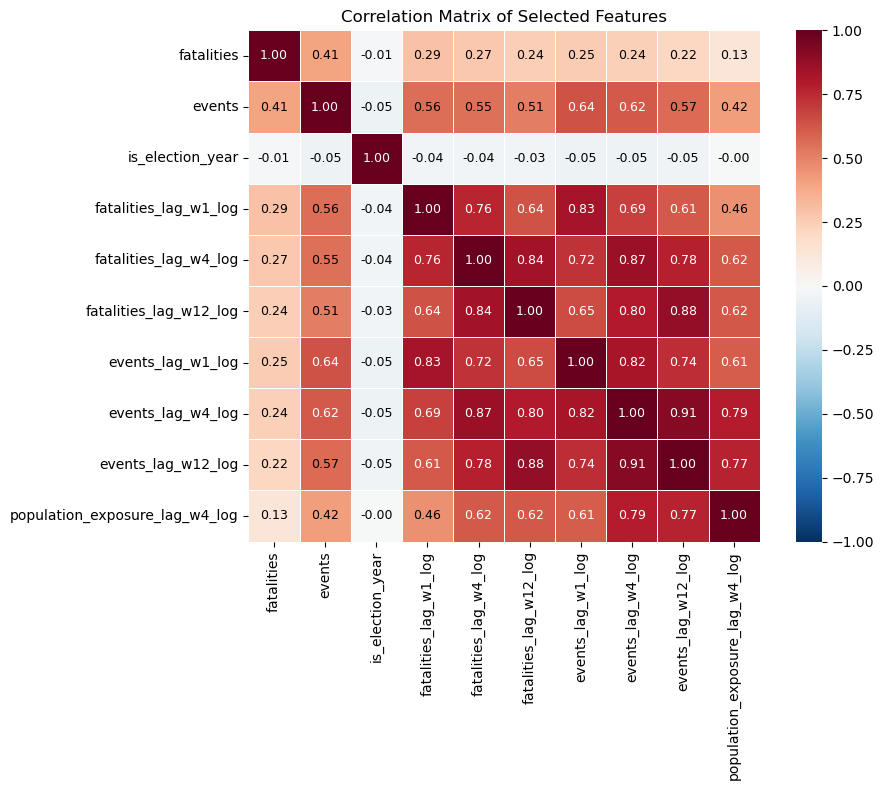

In [379]:
# correlation plot of features vs target

cols = ["fatalities", "events","is_election_year","fatalities_lag_w1_log","fatalities_lag_w4_log","fatalities_lag_w12_log","events_lag_w1_log","events_lag_w4_log","events_lag_w12_log","population_exposure_lag_w4_log"]
import matplotlib, seaborn as sns
print(matplotlib.__version__, sns.__version__)

corr = df[cols].corr()
print(corr.shape)          # should be (7, 7)
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
ax = sns.heatmap(corr, annot=False, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                 square=True, linewidths=0.5)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iloc[i, j]
        ax.text(j + 0.5, i + 0.5, f"{v:.2f}", ha="center", va="center",
                fontsize=9, color="white" if abs(v) > 0.6 else "black")

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()

3.8.0 0.12.2
(11, 11)


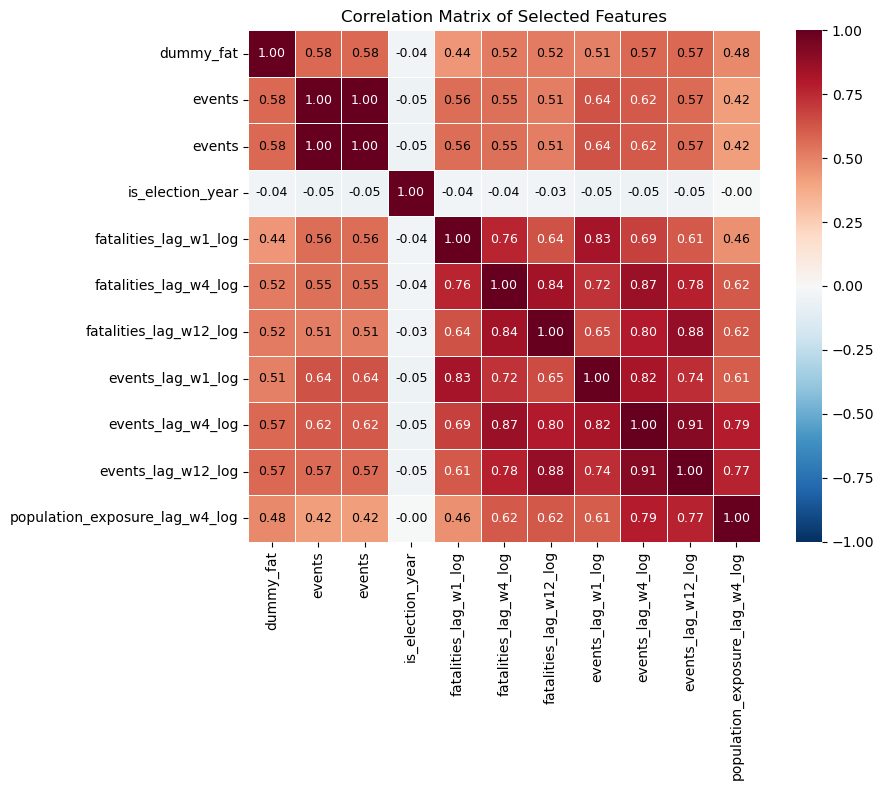

In [380]:

cols = ["dummy_fat", "events","events","is_election_year","fatalities_lag_w1_log","fatalities_lag_w4_log","fatalities_lag_w12_log","events_lag_w1_log","events_lag_w4_log","events_lag_w12_log","population_exposure_lag_w4_log"]
import matplotlib, seaborn as sns
print(matplotlib.__version__, sns.__version__)

corr = df[cols].corr()
print(corr.shape)          # should be (7, 7)
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
ax = sns.heatmap(corr, annot=False, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                 square=True, linewidths=0.5)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iloc[i, j]
        ax.text(j + 0.5, i + 0.5, f"{v:.2f}", ha="center", va="center",
                fontsize=9, color="white" if abs(v) > 0.6 else "black")

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()

3.8.0 0.12.2
(10, 10)


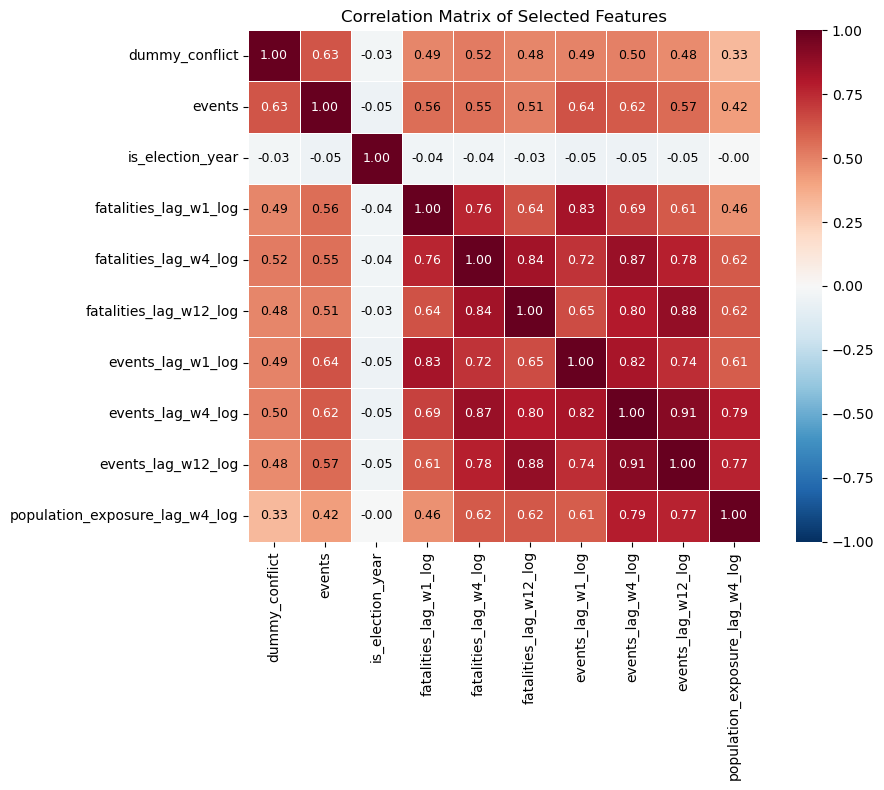

In [381]:

cols = ["dummy_conflict", "events","is_election_year","fatalities_lag_w1_log","fatalities_lag_w4_log","fatalities_lag_w12_log","events_lag_w1_log","events_lag_w4_log","events_lag_w12_log","population_exposure_lag_w4_log"]
import matplotlib, seaborn as sns
print(matplotlib.__version__, sns.__version__)

corr = df[cols].corr()
print(corr.shape)          # should be (7, 7)
corr = df[cols].corr()

plt.figure(figsize=(10, 8))
ax = sns.heatmap(corr, annot=False, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                 square=True, linewidths=0.5)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr.iloc[i, j]
        ax.text(j + 0.5, i + 0.5, f"{v:.2f}", ha="center", va="center",
                fontsize=9, color="white" if abs(v) > 0.6 else "black")

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()

## 2. 3 What does the corr matrix show?
| Feature / Finding                | Correlation / Result                         | Interpretation / Modelling implication                                                                                                                |
| -------------------------------- | -------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------- |
| Population exposure lag 4        | 0.33                                         | Strongest correlation, but largely mechanical because exposure is zero in empty weeks. Exclude to avoid target leakage; test lagged exposure instead. |
| Events (same week)               | 0.58                                         | More events increase the likelihood of at least one fatality. EDA only due to same-week information leakage.                                          |
| Events lag w4                    | 0.57                                         | Strong lagged correlate and candidate predictor.                                                                                                      |
| Events lag w12                   | 0.57                                         | Similar predictive signal to the four-week lag, suggesting persistent conflict activity matters.                                                      |
| Fatalities lag w4                | 0.52                                         | Previous lethal violence is associated with future fatalities.                                                                                        |
| Fatalities lag w12               | 0.52                                         | Longer-term fatality patterns carry predictive signal.                                                                                                |
| Events lag w1                    | 0.51                                         | Recent event activity is predictive, but weaker than longer lag windows.                                                                              |
| Fatalities lag w1                | 0.44                                         | Weakest lagged correlate.                                                                                                                             |
| Election year                    | -0.04                                        | Negligible linear relationship. Test more granular election-period indicators.                                                                        |
| Longer lag windows               | Events: 0.51 → 0.57; fatalities: 0.44 → 0.52 | Longer windows carry more signal than one-week lags, suggesting persistent conflict environments are more informative.                                |
| Binary vs. continuous targets    | Binary targets show stronger correlations    | Binarisation reduces noise associated with zero values and extreme fatality counts.                                                                   |
| `dummy_fat` vs. `dummy_conflict` | 0.57 vs. 0.52 (strongest lagged feature)     | Any-fatality occurrence appears more predictable, while high-intensity conflict is a more demanding early-warning target.                             |
| Class imbalance                  | `dummy_fat` has a higher positive rate       | Class imbalance is milder, but models may simply identify generally active states.                                                                    |
| Baseline evaluation              | Persistence baseline                         | Compare against predicting a fatality this week based on whether one occurred last week.                                                              |